# Ranking Spike Sequences by Fitness and Evaluating Cumulative Tip Scores

In this notebook, we explore multiple ranking methods to prioritize spike sequences based on their fitness estimates. These methods include:

- PyR0 fitness scores  
- EVEscape model scores  
- CoVFit model scores

We then evaluate the performance of each ranking by analyzing how well the top-ranked sequences capture future tips cumulatively over various time slices.

This approach helps identify ranking strategies that best forecast viral evolutionary trends and guide variant surveillance.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [39]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH +"final_df.parquet"
final_df = pd.read_parquet(DATA_PATH)
id_to_seq = load_data(ROOT_PATH + "sequence_dict.parquet")

refSeq = getReference(ROOT_PATH + 'ref_spike_genome.fa')

ver = 'Jan_4_24'

pyro_df = read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

#eve_df = pd.read_csv(ROOT_PATH + 'EVEscape/EVEscore_Wuhan_A')
#eve_df = pd.read_csv(ROOT_PATH + 'EVEscape/EVEscore_Omicron_BA.4')
eve_df = pd.read_csv(ROOT_PATH + 'EVEscape/EVEscore_Omicron_XBB')

In [41]:
start_date = pd.Timestamp("2021-05-15")
end_date = pd.Timestamp("2025-06-15")

filtered_df = final_df[
    final_df["Date"].between(start_date, end_date)
]

sample_mask = ~final_df["Sample_ID"].str.startswith("node_", na=False)
filtered_df = filtered_df[sample_mask]

/tmp/ipykernel_2628169/2338852179.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  filtered_df = filtered_df[sample_mask]


Create Disjoint time interval slices

In [42]:
# --- Define cutoff date ---
cutoff_date = "2024-06-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
disjoint_windows = ['6M_1', '6M_2']

# --- Perform slicing ---
future_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Summary output ---
print(f"Total future slices stored: {len(future_slices)}")

Total future slices stored: 2


In [43]:
# --- Compute tip counts for current circulating sequences ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

min_tip_count = 5
current_seq_df = (
    current_seq_df[current_seq_df['Tip_Count'] >= min_tip_count]
    .reset_index(drop=True)
)

# --- Compute tip counts for each future window ---
future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}



# --- Summary output ---
print(f"Computed current sequence DataFrame with {len(current_seq_df)} unique sequences")
print(f"Computed future sequence DataFrames for {len(future_seq_dfs)} windows")

Computed current sequence DataFrame with 471 unique sequences
Computed future sequence DataFrames for 2 windows


# CoVFit Fitness Score Ranking

We will compute the CoVFit ranking using the precomputed per-sequence average fitness scores.

In [ ]:
import subprocess
from pathlib import Path

# --- Write current sequences to FASTA for CoVFit ---
# Resolve CoVFit_CLI relative to this notebook (scripts/rank_analysis.ipynb)
_notebook_dir = Path.cwd()
if not (_notebook_dir / "rank_analysis.ipynb").exists():
    _notebook_dir = _notebook_dir / "scripts"
COVFIT_DIR = (_notebook_dir / ".." / "CoVFit_CLI").resolve()
fasta_path = Path(ROOT_PATH) / "current_seq_df.fasta"

missing_ids = []
n_written = 0
with open(fasta_path, "w") as fasta_file:
    for seq_id in current_seq_df["Sequence_ID"]:
        seq = id_to_seq.get(seq_id)
        if seq is None:
            missing_ids.append(seq_id)
            continue
        fasta_file.write(f">{seq_id}\n{seq}\n")
        n_written += 1

print(f"Wrote {n_written:,} sequences to {fasta_path}")
if missing_ids:
    print(f"Warning: {len(missing_ids):,} Sequence_IDs missing from id_to_seq")

# --- Run CoVFit CLI ---
covfit_outdir = Path(ROOT_PATH) / cutoff_date / "current_covfit"
covfit_cmd = [
    "./covfit_cli",
    "-i",
    str(fasta_path),
    "-o",
    str(covfit_outdir),
    "-g",
    "-b",
    "16",
    "-f",
    "3",
]
print("Running:", " ".join(covfit_cmd))

result = subprocess.run(
    covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {result.returncode}")

covfit_output = f"{covfit_outdir}/CoVFit_Predictions_fold_3.tsv"
print(f"CoVFit predictions written to {covfit_output}")


In [44]:
# --- Load CoVFit fitness scores ---
covfit_outdir = Path(ROOT_PATH) / cutoff_date / "current_covfit"
covfit_output = covfit_outdir / "CoVFit_Predictions_fold_3.tsv"

covfit_score_df = pd.read_csv(covfit_output, sep="\t")
covfit_score_df = covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

current_seq_df = current_seq_df.merge(
    covfit_score_df[["Sequence_ID", "fitness_mean"]],
    on="Sequence_ID",
    how="left",
)

print(f"Loaded {len(covfit_score_df):,} CoVFit score entries")
print(f"Merged fitness scores into current sequence DataFrame with {len(current_seq_df):,} sequences")


Loaded 471 CoVFit score entries
Merged fitness scores into current sequence DataFrame with 471 sequences


# PyR0 and EVEscape Ranking

Rank sequences using:
- **PyR₀ score**: product of R/Rₐ values across all spike mutations.  
- **EVEscape score**: sum of EVEsape scores across all soike mutations using Wuhan_A scoring.  


In [45]:
# --- Build mutation-to-score dictionaries ---
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

# EVEscape scores every mutation against its own backbone, so the lookup key is
# that backbone's residue: wt + pos + mut.
mutation_score_dict_eve = (
    eve_df.assign(key=eve_df["wt"] + eve_df["pos"].astype(str) + eve_df["mut"])
    .set_index("key")["EVEscape"]
    .to_dict()
)

# --- Reconstruct the EVEscape backbone and express it against Wuhan ---
# 'wt' is the backbone's residue at each site, so the sites where it disagrees
# with ref_spike_genome are exactly the backbone's mutations. Empty for Wuhan.
eve_backbone = eve_df.drop_duplicates("pos").set_index("pos")["wt"]
eve_ref_mutations = {
    pos: allele for pos, allele in eve_backbone.items() if refSeq[pos - 1] != allele
}

# --- Summary output ---
print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")
print(f"Loaded {len(mutation_score_dict_eve)} EVEscape mutation scores")
print(
    f"EVEscape backbone differs from Wuhan at {len(eve_ref_mutations)} site(s): "
    + (", ".join(f"{refSeq[p - 1]}{p}{a}" for p, a in sorted(eve_ref_mutations.items()))
       or "none (Wuhan)")
)

Loaded 2478 PyR₀ mutation scores
Loaded 24187 EVEscape mutation scores
EVEscape backbone differs from Wuhan at 28 site(s): T19I, V83A, G142D, H146Q, Q183E, V213E, G339H, R346T, N440K, V445P, G446S, N460K, S477N, T478K, E484A, F486S, F490S, Q498R, N501Y, Y505H, D614G, H655Y, N679K, P681H, N764K, D796Y, Q954H, N969K


In [46]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)


# --- Re-express each sequence's mutations against the EVEscape backbone ---
def to_eve_ref_mutations(mutations):
    """Convert Wuhan-relative mutations to backbone-relative ones.

    At every site touched by the sequence or the backbone, compare the residue
    each one carries and emit a mutation only where they differ:
      - same residue            -> dropped, the sequence already matches
      - different residue       -> backbone residue becomes the wild type
      - backbone site only      -> reversal back to the Wuhan residue
      - sequence site only      -> kept unchanged (backbone is Wuhan there)
    Mutations that do not parse (stop codons / deletions) are dropped, since
    they carry no EVEscape score.
    With EVEscore_Wuhan_A the backbone is empty, so this returns 'Mutations'.
    """
    seq_alleles = {}
    for m in mutations:
        _wt, pos, alt = get_mutation_pattern(m)
        if not pos:
            continue
        seq_alleles[pos] = alt

    rebased = []
    for pos in sorted(set(seq_alleles) | set(eve_ref_mutations)):
        wuhan = refSeq[pos - 1]
        ref_allele = eve_ref_mutations.get(pos, wuhan)
        seq_allele = seq_alleles.get(pos, wuhan)
        if seq_allele == ref_allele:
            continue
        rebased.append(f"S:{ref_allele}{pos}{seq_allele}")
    return tuple(rebased)


current_seq_df["eve_ref_mutations"] = [
    to_eve_ref_mutations(muts) for muts in current_seq_df["Mutations"]
]

# --- Compute EVEscape fitness scores ---
current_seq_df = add_fitness_scores_eve(
    current_seq_df, mutation_score_dict_eve, mutations_col="eve_ref_mutations"
)

# --- Summary output ---
print(f"Computed mutations and fitness scores for {len(current_seq_df)} sequences")

Computed mutations and fitness scores for 471 sequences


In [47]:
# --- Build oracle ranking of current sequences for each future window ---
oracle_rankings = build_oracle_current_rankings(
    current_seq_df,
    future_seq_dfs,
    random_state=0,
)

print(f"Built oracle rankings for {len(oracle_rankings)} time windows")

Built oracle rankings for 2 time windows


In [48]:
# --- Compute cumulative tip percentages for all ranking methods ---
rank_results = compute_cumulative_tip_percentages_fast(
    current_seq_df,
    future_seq_dfs,
    oracle_rankings=oracle_rankings,
    max_rank=None
)

# --- Summary output ---
print(f"Computed cumulative tip percentages for {len(rank_results)} future time windows")

Computed cumulative tip percentages for 2 future time windows


In [50]:
# --- Compute normalized AUC for each ranking method ---
auc_scores = compute_auc_for_rank_results(rank_results)
df = pd.DataFrame(auc_scores)
df.index.name = 'Model'

print(cutoff_date, df)

2024-06-01                6M_1      6M_2
Model                        
pyro       0.408394  0.127886
eve        0.468454  0.248666
covfit     0.585289  0.242924
tip_count  0.642120  0.226790
oracle     0.684881  0.271955


# Plotting Results in a six-month period

The following plots visualize the performance of different ranking methods in capturing future tips.  
Each main panel shows the cumulative fraction of future tips captured by the top-ranked sequences over a given time interval.  
Inset panels display the corresponding normalized AUC scores for each method, with a reference line indicating the achievable ceiling.

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np

sns.set_style("whitegrid")
sns.set_context("talk")

def plot_1x2_cumulative_auto(rank_results, auc_scores, cutoff_date):
    slice_keys = list(rank_results.keys())[:4]

    legend_map = {
        "pyro": "PyR0 Fitness Score",
        "eve": "EVEscape Fitness Score",
        "covfit": "CoVFit Fitness Score",
        "tip_count": "Prevalence Score",
        "oracle": "Theoretical Best Ranking",
    }
    panel_head = {
        '6M_1' : '0 - 6 months',
        '6M_2' : '6 - 12 months'
    }

    base_palette = sns.color_palette("colorblind", n_colors=4)
    color_map = {
        "pyro": base_palette[0],
        "eve": base_palette[1],
        "covfit": base_palette[2],
        "tip_count": base_palette[3],
        "oracle": "black",
    }

    fig, axes = plt.subplots(1, 2, figsize=(30, 12), sharex=True, sharey=True)
    axes = axes.flatten()
    plt.subplots_adjust(wspace=0.51, top=0.865)  # Add this line to create space between plots
    fig.suptitle(f'Fraction of Future Sequences Captured by Ranking Models: {cutoff_date}', fontsize=30, y = 0.95)

    legend_handles = []
    legend_labels = []

    for i, key in enumerate(slice_keys):
        df = rank_results[key]
        ax = axes[i]

        tip_cols = [col for col in df.columns if col.startswith('%_tips_')]
        methods = [col.replace('%_tips_', '') for col in tip_cols]
        bar_methods = [m for m in methods if m != "oracle"]

        # Main lineplots
        for method in methods:
            label_name = legend_map.get(method, method)
            line_kwargs = {
                "data": df,
                "x": "Rank",
                "y": f"%_tips_{method}",
                "ax": ax,
                "linewidth": 2.5,
                "color": color_map[method],
                "legend": False,
            }
            if method == "oracle":
                line_kwargs["linestyle"] = "--"
            sns.lineplot(**line_kwargs)
            if label_name not in legend_labels:
                legend_handles.append(ax.lines[-1])
                legend_labels.append(label_name)

        # X-axis ticks
        max_rank = int(df['Rank'].max())
        tick_base = 10 if max_rank <= 200 else 100 if max_rank <= 2000 else 1000
        tick_vals = list(range(tick_base, max_rank + 1, tick_base))
        if 10 not in tick_vals:
            tick_vals.insert(0, 10)
        if 500 not in tick_vals and 500 <= max_rank:
            tick_vals.append(500)
        tick_vals = sorted(set(tick_vals))
        tick_labels = [f'{x//1000}K' if x >= 1000 else str(x) for x in tick_vals]
        ax.set_xticks(tick_vals)
        ax.set_xticklabels(tick_labels, rotation=45, fontsize=20)
        ax.tick_params(axis='y', labelsize=20)

        ax.set_title(f'Fraction of Future Sequences Captured in {panel_head[key]}', fontsize=28)
        ax.set_xlabel('Top Rank', fontsize=26)
        ax.set_ylabel('Normalized Tip Score', fontsize=26)

        # --- Inset AUC bar plot, bottom-right, no x-ticks ---
        if auc_scores is not None and key in auc_scores:
            inset_ax = inset_axes(ax, width="25%", height="25%", loc='lower right', borderpad=1)
            # Theoretical maximum: the AUC of the oracle, which ranks circulating
            # variants by their observed future prevalence. By the rearrangement
            # inequality no ordering encloses more area, so this is the attainable
            # bound -- unlike the height-1 rectangle, which no ranking can trace.
            best_auc = auc_scores[key]["oracle"]
            auc_values = [auc_scores[key].get(m, 0) for m in bar_methods]
            inset_ax.bar(range(len(bar_methods)), auc_values, color=[color_map[m] for m in bar_methods])
            inset_ax.set_title("Normalized AUC", fontsize=20)
            inset_ax.set_xticks([])  # remove x-ticks
            inset_ax.set_xlabel("")
            inset_ax.tick_params(axis='y', labelsize=20)
            inset_ax.set_ylim(0, 1.05)
            inset_ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00])
            inset_ax.set_yticklabels(['0', '0.25', '0.50', '0.75', '1.00'])

            # --- Modification 1: remove grid lines ---
            inset_ax.grid(False)

            # --- Modification 2: theoretical maximum AUC (perfect ranking) ---
            inset_ax.axhline(y=best_auc, color='black', linestyle='--', linewidth=2)

    # Shared legend outside
    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc='center',
        bbox_to_anchor=(0.51, 0.5),
        fontsize=20,
        title="Ranking Methods",
        title_fontsize=22
    )

    plt.savefig(Path(ROOT_PATH) / cutoff_date / 'overlap.svg', format='svg', bbox_inches='tight', dpi=300)
    plt.show()

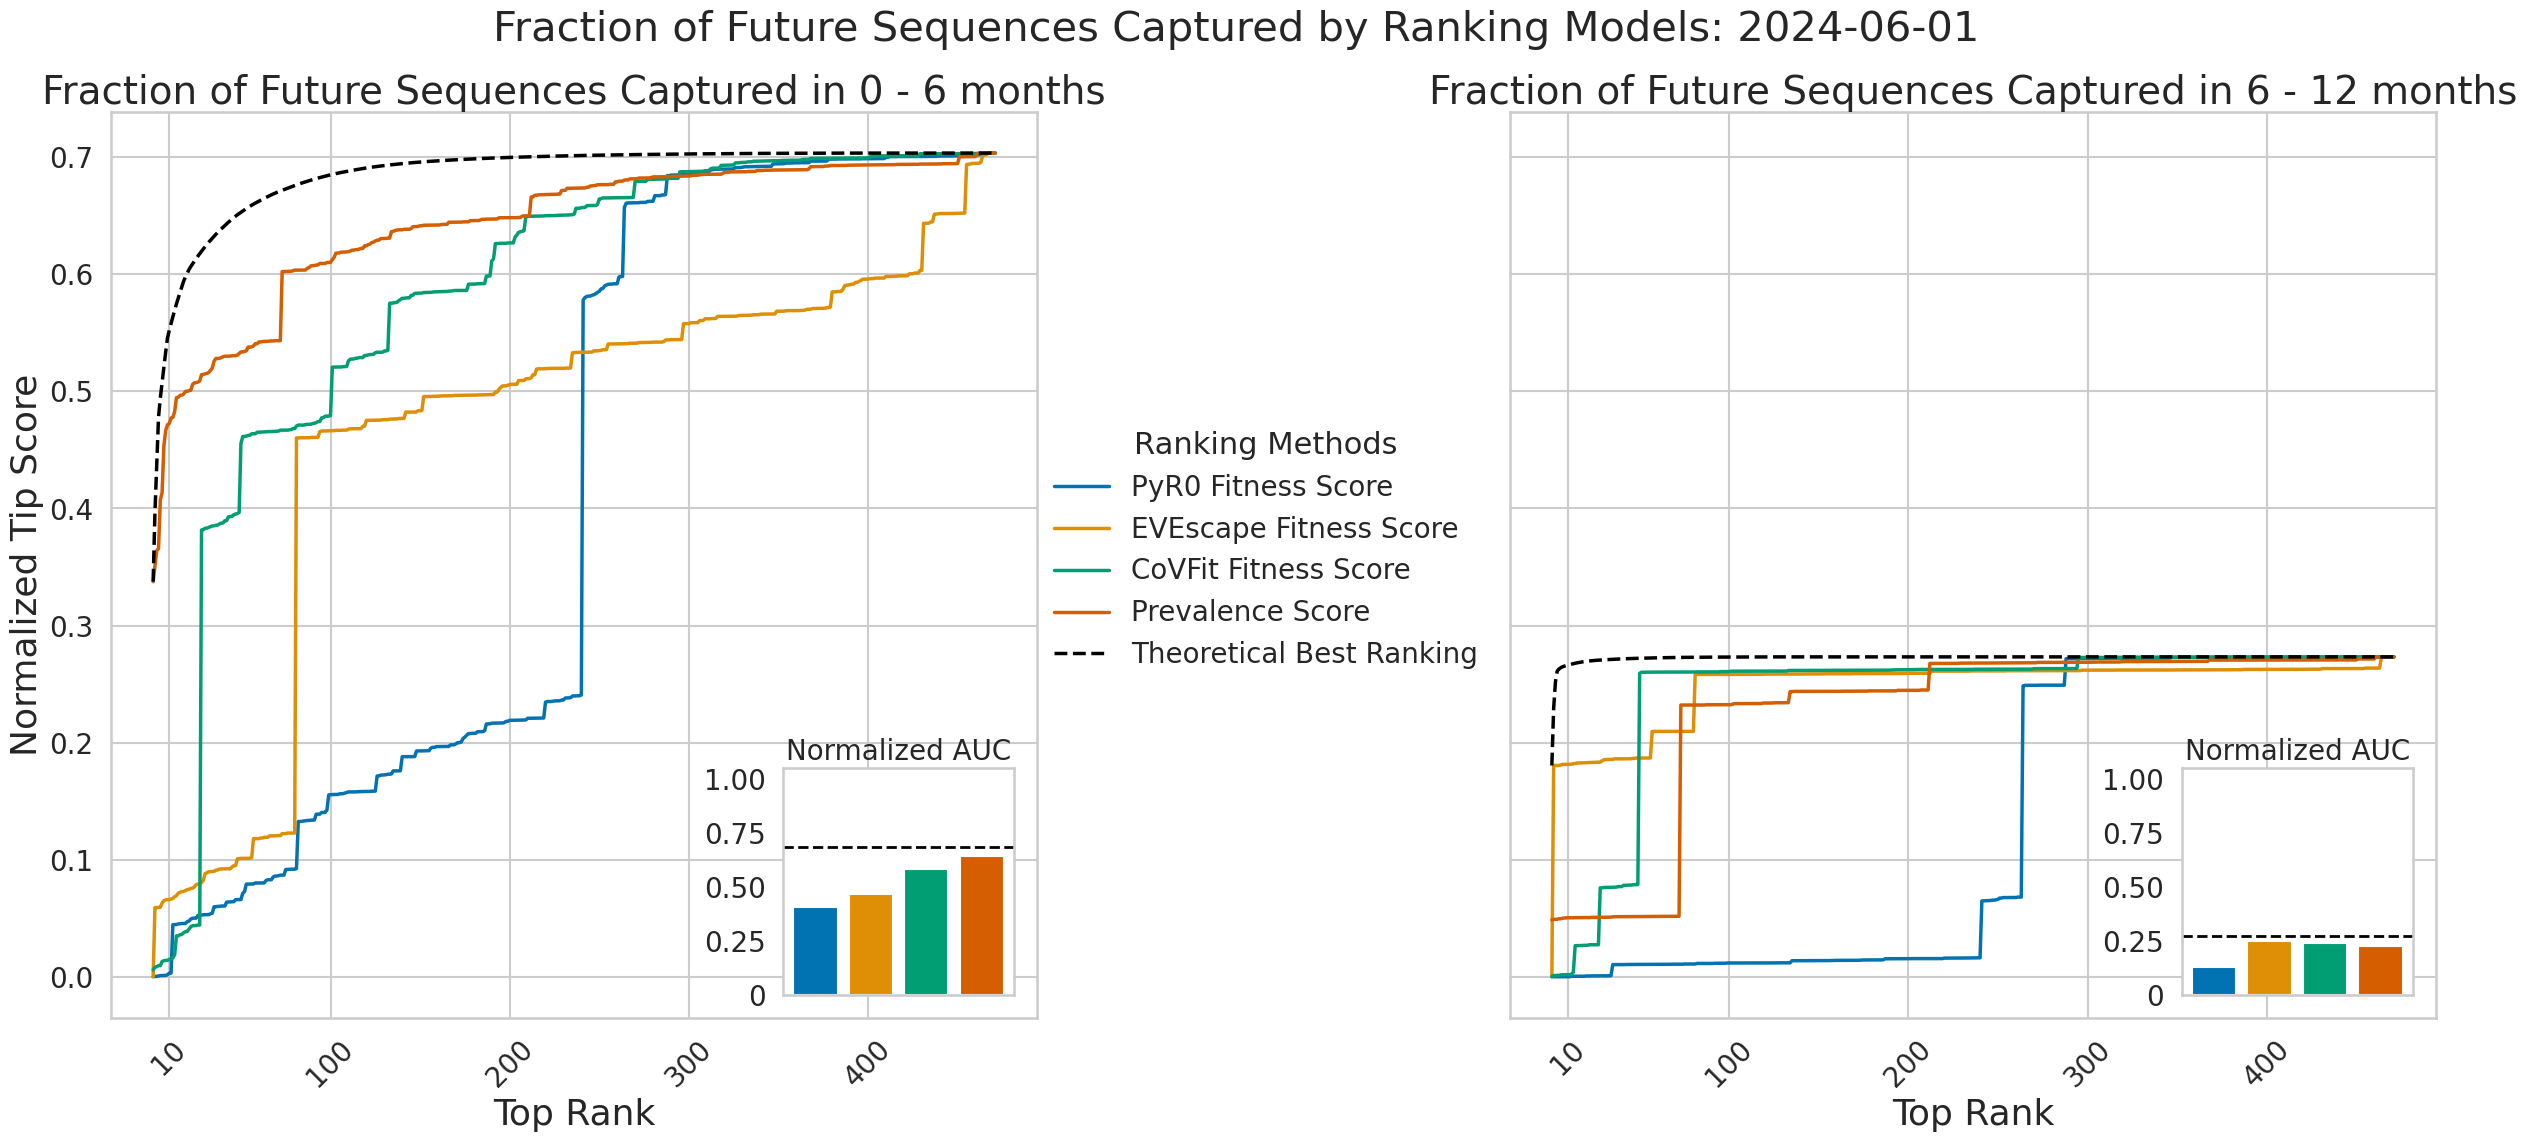

In [52]:
plot_1x2_cumulative_auto(rank_results=rank_results,
                         auc_scores=auc_scores,
                         cutoff_date=cutoff_date)